In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(11)
LATENT = 2

## 1. Data

In [2]:
(x_tr, _), (x_te, _) = keras.datasets.mnist.load_data()
x_tr = x_tr.reshape(-1, 784).astype("float32") / 255.0
x_te = x_te.reshape(-1, 784).astype("float32") / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 2. Encoder, sampling layer and decoder

In [3]:
class Sampling(layers.Layer):
    """Reparameterisation trick: z = mu + sigma * eps."""
    def call(self, inputs):
        mu, log_var = inputs
        eps = tf.random.normal(tf.shape(mu))
        return mu + tf.exp(0.5 * log_var) * eps

enc_in = keras.Input(shape=(784,))
h = layers.Dense(256, activation="relu")(enc_in)
mu = layers.Dense(LATENT, name="mu")(h)
log_var = layers.Dense(LATENT, name="log_var")(h)
z = Sampling()([mu, log_var])
encoder = keras.Model(enc_in, [mu, log_var, z], name="encoder")

dec_in = keras.Input(shape=(LATENT,))
d = layers.Dense(256, activation="relu")(dec_in)
decoder = keras.Model(dec_in, layers.Dense(784, activation="sigmoid")(d), name="decoder")

## 3. VAE model with ELBO loss

In [4]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder = encoder, decoder
        self.total_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon")
        self.kl_tracker = keras.metrics.Mean(name="kl")

    @property
    def metrics(self):
        return [self.total_tracker, self.recon_tracker, self.kl_tracker]

    def call(self, x):
        return self.decoder(self.encoder(x)[2])

    def train_step(self, x):
        with tf.GradientTape() as tape:
            mu, log_var, z = self.encoder(x)
            x_hat = self.decoder(z)
            # summed over pixels, averaged over the batch
            recon = tf.reduce_mean(tf.reduce_sum(
                keras.losses.binary_crossentropy(x, x_hat)[..., None], axis=-1) * 784)
            kl = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + log_var - tf.square(mu) - tf.exp(log_var), axis=1))
            loss = recon + kl
        grads = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_tracker.update_state(loss)
        self.recon_tracker.update_state(recon)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))
vae.fit(x_tr, epochs=10, batch_size=128)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - kl: 9.2788 - loss: 205.7273 - recon: 196.4485
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - kl: 4.9795 - loss: 171.0350 - recon: 166.0555
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - kl: 4.9711 - loss: 167.3624 - recon: 162.3914
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - kl: 5.0495 - loss: 165.2157 - recon: 160.1661
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - kl: 5.1110 - loss: 163.4400 - recon: 158.3290
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - kl: 5.1953 - loss: 161.9290 - recon: 156.7337
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - kl: 5.2905 - loss: 160.6680 - recon: 155.3775
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - kl: 5.3701 - loss: 159.5611 - recon: 154.1909
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - kl: 5.4254 - loss: 158.5990 - recon: 153.1735
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - kl: 5.4781 - loss: 157.7774 - re

## 4. Reconstructions

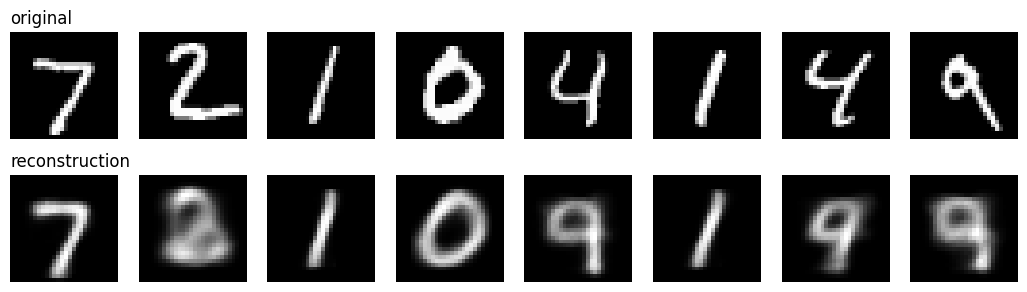

In [5]:
x_demo = x_te[:8]
recon = vae.predict(x_demo, verbose=0)

fig, axes = plt.subplots(2, 8, figsize=(13, 3.4))
for i in range(8):
    axes[0, i].imshow(x_demo[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(recon[i].reshape(28, 28), cmap="gray");  axes[1, i].axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("reconstruction", loc="left")
plt.show()

## 5. Generate new digits by walking the latent space

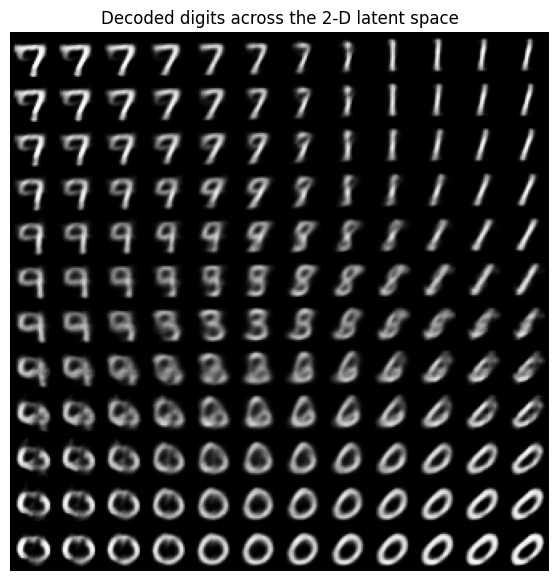

In [6]:
N = 12
grid = np.linspace(-3, 3, N)
canvas = np.zeros((N * 28, N * 28))
for r, zy in enumerate(grid[::-1]):
    for c, zx in enumerate(grid):
        digit = decoder.predict(np.array([[zx, zy]]), verbose=0)[0].reshape(28, 28)
        canvas[r * 28:(r + 1) * 28, c * 28:(c + 1) * 28] = digit

plt.figure(figsize=(7, 7)); plt.imshow(canvas, cmap="gray")
plt.title("Decoded digits across the 2-D latent space"); plt.axis("off"); plt.show()